# 13. Observability predictor over time

This notebook is the final temporal sanity check for the learned observability predictor.

It evaluates checkpoint **008** on one held-out KAIST sequence and plots the predicted observability through time under:

1. raw measurements;
2. frame randomization only;
3. current-prior perturbation only;
4. measurement noise only;
5. sampling-rate augmentation only, with a freshly recomputed Fisher target;
6. combined nuisance augmentations used during training;
7. the full trained augmentation combination, including probabilistic sampling-rate reduction and online Fisher recomputation;
8. calibration-event augmentation as an out-of-distribution stress test;
9. optionally, the full trained augmentation combination plus calibration events.

Only the informative coordinates are plotted:

\[
(\phi_x,\phi_y,\phi_z,\tau)
\]

for both IMU and LiDAR calibration groups.

For nuisance augmentations, the desired reference is the original raw observability. For sampling-rate augmentation, the desired reference is the observability recomputed after the rate change. Calibration-event Fisher values are shown only as an exploratory static-model diagnostic because an event window does not correspond to one static calibration over the whole window.

Event start times are drawn as vertical lines. Their transition durations are shown as lightly shaded spans.


## 1. Imports and repository root


In [1]:
from pathlib import Path
import inspect
import json
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

ROOT = Path.cwd()
for candidate in (ROOT, *ROOT.parents):
    if (candidate / "src" / "obscalib").exists():
        ROOT = candidate
        break
else:
    raise FileNotFoundError("Could not locate the nn-obs-calib repository root containing src/obscalib.")

if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from kaist_dataset.dataset import KAISTCalibrationDataset, KAISTRigCalibration, build_kaist_sequence_specs

from obscalib.augmentations.config import AugmentationConfig, CalibrationEventConfig, FrameRandomizationConfig, NoiseAugmentationConfig, PerturbationMagnitudeConfig, PriorPerturbationConfig, SamplingRateAugmentationConfig, SE3NoiseConfig, VectorNoiseConfig
from obscalib.augmentations.pipeline import AugmentationPipeline
from obscalib.augmentations.profiles import TransitionProfile
from obscalib.config import ObservabilityPredictionHeadConfig, ObservabilityPredictionModelConfig, TransformerConfig, WindowingConfig
from obscalib.data.collation import collate_windows
from obscalib.data.device import window_batch_to
from obscalib.data.structures import MeasurementType
from obscalib.geometry.processing import GeometryProcessor
from obscalib.models.observability_prediction_model import ObservabilityPredictionModel
from obscalib.observability.estimators import ObservabilityMatrixEstimator
from obscalib.observability.layout import CalibrationParameterLayout
from obscalib.observability.mappings import dimensionless_soft_projector_observability
from obscalib.observability.numerics import ObservabilityNumericsConfig
from obscalib.observability.structures import ObservabilityResult
from obscalib.tokenization.tokenizer import Tokenizer
from obscalib.training.checkpoint import load_training_checkpoint

print("Repository root:", ROOT)
print("PyTorch:", torch.__version__)


Repository root: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib
PyTorch: 2.7.1+cu126


## 2. Experiment configuration


In [2]:
##################################################
# Sequence / checkpoint
##################################################

KAIST_DATASET_ROOT = Path("/mnt/d/Downloads/MobRobLab/KAISTDataset")
LIDAR_POSE_ROOT = Path("/home/camel/Skoltech/phd_proposal/data/KAISTDataset")

TRAIN_NAMES = [
    "Urban08",
    "Urban12",
    "Urban13",
    "Urban14",
    "Urban15",
    "Urban16",
]

TEST_NAMES = [
    "Urban38",
    "Urban39",
]

SEQUENCE_NAME = "Urban38"

CHECKPOINT_RUN_NAME = "kaist_observability_predictor_008"
BEST_MODEL_CHECKPOINT = ROOT / "runs" / CHECKPOINT_RUN_NAME / "best.pt"

##################################################
# Reproducibility / plotting
##################################################

RANDOM_SEED = 67890

# None means the full sequence. Set integers to zoom without changing evaluation.
PLOT_START_WINDOW = None
PLOT_END_WINDOW = None

# The event probability is intentionally lower than a future training probability
# so event markers remain readable over a complete sequence.
EVENT_SANITY_PROBABILITY = 0.15

RUN_FULL_PLUS_EVENT_STRESS_TEST = True
RECOMPUTE_STATIC_EVENT_FISHER = True

##################################################
# Windowing
##################################################

WINDOW_DURATION_S = 5.0
WINDOW_STRIDE_S = 5.0
MAX_SAMPLES_PER_SENSOR = 700

##################################################
# Observability target
##################################################

CALIBRATION_KEYS = ("imu", "lidar")
CALIBRATION_COMPONENT_NAMES = ("phi_x", "phi_y", "phi_z", "rho_x", "rho_y", "rho_z", "tau")
INFORMATIVE_COMPONENTS = ("phi_x", "phi_y", "phi_z", "tau")

DIMENSIONLESS_ROTATION_SCALE_RAD = np.deg2rad(5.0)
DIMENSIONLESS_TRANSLATION_SCALE_M = 0.05
DIMENSIONLESS_TIME_OFFSET_SCALE_S = 0.015

DIMENSIONLESS_CALIBRATION_SCALE = (
    DIMENSIONLESS_ROTATION_SCALE_RAD,
    DIMENSIONLESS_ROTATION_SCALE_RAD,
    DIMENSIONLESS_ROTATION_SCALE_RAD,
    DIMENSIONLESS_TRANSLATION_SCALE_M,
    DIMENSIONLESS_TRANSLATION_SCALE_M,
    DIMENSIONLESS_TRANSLATION_SCALE_M,
    DIMENSIONLESS_TIME_OFFSET_SCALE_S,
)

LAMBDA_VALUE_SETTING = 0.25
PROJECTION_NUMERICAL_TOLERANCE = 1e-10
USE_NJIT_OBSERVABILITY = True
REFERENCE_LIDAR_STREAM_KEY = "lidar"

##################################################
# Predictor
##################################################

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MODEL_DTYPE = torch.float32

MEASUREMENT_DIM = 6
TOKEN_INPUT_DIM = MEASUREMENT_DIM + 2

D_MODEL = 128
N_HEADS = 8
NUM_TRANSFORMER_LAYERS = 8
DIM_FEEDFORWARD = 512
TRANSFORMER_DROPOUT = 0.1

HEAD_HIDDEN_DIMS = (128, 64)
HEAD_DROPOUT = 0.1
HEAD_MODE = "shared"

##################################################
# Cache
##################################################

OUTPUT_DIR = ROOT / "tmp" / "observability_predictor_over_time"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

RAW_TEST_TARGET_CACHE_PATH = ROOT / "tmp" / "observability_targets" / "test.pt"

print("Sequence:", SEQUENCE_NAME)
print("Checkpoint:", BEST_MODEL_CHECKPOINT)
print("Device:", DEVICE)
print("Output directory:", OUTPUT_DIR)


Sequence: Urban38
Checkpoint: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_observability_predictor_008/best.pt
Device: cuda
Output directory: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/tmp/observability_predictor_over_time


## 3. Build train/test datasets and select the held-out sequence


In [3]:
T_B_L = np.array([
    [-0.514066, -0.702201, -0.492595, -0.440699],
    [0.486485, -0.711672, 0.506809, 0.397052],
    [-0.706447, 0.0208933, 0.707457, 1.90953],
    [0.0, 0.0, 0.0, 1.0],
], dtype=float)

T_I_B = np.array([
    [1.0, 0.0, 0.0, -0.07],
    [0.0, 1.0, 0.0, 0.0],
    [0.0, 0.0, 1.0, 1.7],
    [0.0, 0.0, 0.0, 1.0],
], dtype=float)

rig_calibration = KAISTRigCalibration(
    T_B_I=np.linalg.inv(T_I_B),
    T_B_L=T_B_L,
    tau_imu_s=0.0,
    tau_lidar_s=0.0,
)

windowing_config = WindowingConfig(
    window_duration_s=WINDOW_DURATION_S,
    window_stride_s=WINDOW_STRIDE_S,
    max_samples_per_sensor=MAX_SAMPLES_PER_SENSOR,
)

train_specs = build_kaist_sequence_specs(
    sequence_names=TRAIN_NAMES,
    kaist_dataset_root=KAIST_DATASET_ROOT,
    lidar_pose_root=LIDAR_POSE_ROOT,
)

test_specs = build_kaist_sequence_specs(
    sequence_names=TEST_NAMES,
    kaist_dataset_root=KAIST_DATASET_ROOT,
    lidar_pose_root=LIDAR_POSE_ROOT,
)

train_dataset = KAISTCalibrationDataset(
    train_specs,
    rig_calibration,
    windowing_config,
    measurement_dtype=torch.float32,
    source_timestamp_dtype=torch.float64,
    window_timestamp_dtype=torch.float32,
)

test_dataset = KAISTCalibrationDataset(
    test_specs,
    rig_calibration,
    windowing_config,
    measurement_dtype=torch.float32,
    source_timestamp_dtype=torch.float64,
    window_timestamp_dtype=torch.float32,
)

sequence_dataset_indices = np.asarray(
    [
        dataset_index
        for dataset_index in range(len(test_dataset))
        if test_dataset.sequence_name_for_window(dataset_index) == SEQUENCE_NAME
    ],
    dtype=int,
)

if sequence_dataset_indices.size == 0:
    raise ValueError(f"No windows found for sequence {SEQUENCE_NAME!r}.")

sequence_positions = np.arange(sequence_dataset_indices.size, dtype=int)
window_start_times_s = sequence_positions.astype(float) * WINDOW_STRIDE_S
window_center_times_s = window_start_times_s + 0.5 * WINDOW_DURATION_S

print(train_dataset.summary())
print()
print(test_dataset.summary())
print()
print(f"{SEQUENCE_NAME}: {len(sequence_dataset_indices)} windows")


KAISTCalibrationDataset: 2005 windows from 6 sequences
approximate tensor storage: 37.4 MiB
  Urban08: windows=59, duration=297.8s, IMU=30800, LiDAR=2952
  Urban12: windows=473, duration=2478.6s, IMU=249198, LiDAR=23222
  Urban13: windows=223, duration=1446.5s, IMU=145492, LiDAR=10536
  Urban14: windows=286, duration=1737.0s, IMU=174681, LiDAR=13638
  Urban15: windows=184, duration=1034.3s, IMU=104795, LiDAR=9011
  Urban16: windows=780, duration=4458.2s, IMU=449215, LiDAR=37703

KAISTCalibrationDataset: 699 windows from 2 sequences
approximate tensor storage: 13.1 MiB
  Urban38: windows=349, duration=2147.3s, IMU=216225, LiDAR=17005
  Urban39: windows=350, duration=1856.3s, IMU=186682, LiDAR=17195

Urban38: 349 windows


## 4. Scientific observability estimator


In [4]:
calibration_layout = CalibrationParameterLayout.from_calibration_keys(CALIBRATION_KEYS)

GYRO_MEASUREMENT_COVARIANCE = torch.tensor([
    [2.96367932e-06, -1.94438078e-07, -4.83643437e-07],
    [-1.94438078e-07, 1.89162212e-06, 1.09062693e-07],
    [-4.83643437e-07, 1.09062693e-07, 1.88843506e-06],
], dtype=torch.float64)

ACCEL_MEASUREMENT_COVARIANCE = torch.tensor([
    [4.85003041e-03, -9.25262862e-05, 2.14219676e-04],
    [-9.25262862e-05, 1.51980006e-03, -1.13182999e-03],
    [2.14219676e-04, -1.13182999e-03, 2.29777687e-03],
], dtype=torch.float64)

LIDAR_SCAN_TO_MAP_ROTATION_COVARIANCE = torch.tensor([
    [1.10442767e-05, 9.46809587e-07, 3.78536515e-06],
    [9.46809587e-07, 3.35041997e-05, 1.90008728e-06],
    [3.78536515e-06, 1.90008728e-06, 1.10553483e-05],
], dtype=torch.float64)

LIDAR_SCAN_TO_MAP_TRANSLATION_COVARIANCE = torch.tensor([
    [0.00843466, 0.00266052, 0.00702046],
    [0.00266052, 0.01444850, 0.00225705],
    [0.00702046, 0.00225705, 0.00704268],
], dtype=torch.float64)

LIDAR_SCAN_TO_MAP_COVARIANCE = torch.zeros((6, 6), dtype=torch.float64)
LIDAR_SCAN_TO_MAP_COVARIANCE[:3, :3] = LIDAR_SCAN_TO_MAP_ROTATION_COVARIANCE
LIDAR_SCAN_TO_MAP_COVARIANCE[3:, 3:] = LIDAR_SCAN_TO_MAP_TRANSLATION_COVARIANCE

residual_covariance_by_stream = {
    "gyro": GYRO_MEASUREMENT_COVARIANCE,
    "accel": ACCEL_MEASUREMENT_COVARIANCE,
    "lidar": 2.0 * LIDAR_SCAN_TO_MAP_COVARIANCE,
}

GRAVITY_WORLD = torch.tensor([0.0, 0.0, 9.81], dtype=torch.float64)
gyro_bias_by_calibration_key = {"imu": torch.zeros(3, dtype=torch.float64)}

observability_numerics = ObservabilityNumericsConfig(
    relative_tolerance=PROJECTION_NUMERICAL_TOLERANCE,
    parameter_scales=None,
)


In [5]:
def relative_lidar_body_trajectory_provider(measurements, metadata, calibration, reference_timebase):
    stream_key = reference_timebase.stream_key

    if stream_key != REFERENCE_LIDAR_STREAM_KEY:
        raise ValueError(f"Expected reference stream {REFERENCE_LIDAR_STREAM_KEY!r}, got {stream_key!r}.")

    stream = measurements[stream_key]

    if stream.interval_start_timestamps is None:
        raise ValueError("Reference LiDAR stream must carry interval_start_timestamps.")

    calibration_key = metadata[stream_key].calibration_key
    T_B_L_current = calibration[calibration_key].transform

    if T_B_L_current.ndim == 3:
        if T_B_L_current.shape[0] != 1:
            raise ValueError("Unbatched trajectory provider expects one calibration state.")
        T_B_L_current = T_B_L_current[0]

    T_B_L_current = T_B_L_current.to(device="cpu", dtype=torch.float64)
    T_L_B_current = torch.linalg.inv(T_B_L_current)

    relative_lidar_poses = stream.values
    interval_starts = stream.interval_start_timestamps
    interval_ends = stream.timestamps

    if relative_lidar_poses.ndim == 4:
        if relative_lidar_poses.shape[0] != 1:
            raise ValueError("Trajectory provider expects an unbatched stream or singleton batch.")
        relative_lidar_poses = relative_lidar_poses[0]
        interval_starts = interval_starts[0]
        interval_ends = interval_ends[0]

    relative_lidar_poses = relative_lidar_poses.to(device="cpu", dtype=torch.float64)
    interval_starts = interval_starts.to(device="cpu", dtype=torch.float64)
    interval_ends = interval_ends.to(device="cpu", dtype=torch.float64)
    reference_timestamps = reference_timebase.timestamps.to(device="cpu", dtype=torch.float64)

    poses_by_time = {}
    current_pose = torch.eye(4, dtype=torch.float64)

    for interval_index in range(relative_lidar_poses.shape[0]):
        start_time = float(interval_starts[interval_index].item())
        end_time = float(interval_ends[interval_index].item())

        poses_by_time[start_time] = current_pose

        relative_body_motion = T_B_L_current @ relative_lidar_poses[interval_index] @ T_L_B_current
        current_pose = current_pose @ relative_body_motion

        poses_by_time[end_time] = current_pose

    available_times = np.asarray(sorted(poses_by_time), dtype=float)
    trajectory_poses = []

    for timestamp in reference_timestamps:
        query_time = float(timestamp.item())
        nearest_index = int(np.argmin(np.abs(available_times - query_time)))
        nearest_time = float(available_times[nearest_index])

        if abs(nearest_time - query_time) > 1e-6:
            raise ValueError(
                f"Could not construct nominal pose at reference timestamp {query_time:.9f}; "
                f"nearest available time is {nearest_time:.9f}."
            )

        trajectory_poses.append(poses_by_time[nearest_time])

    return torch.stack(trajectory_poses, dim=0)


estimator_signature = inspect.signature(ObservabilityMatrixEstimator.__init__)

estimator_kwargs = {
    "calibration_layout": calibration_layout,
    "trajectory_provider": relative_lidar_body_trajectory_provider,
    "residual_covariance_by_stream": residual_covariance_by_stream,
}

optional_estimator_kwargs = {
    "gravity_world": GRAVITY_WORLD,
    "gyro_bias_by_calibration_key": gyro_bias_by_calibration_key,
    "numerics": observability_numerics,
    "njit": USE_NJIT_OBSERVABILITY,
    "reference_stream_key": REFERENCE_LIDAR_STREAM_KEY,
}

for argument_name, argument_value in optional_estimator_kwargs.items():
    if argument_name in estimator_signature.parameters:
        estimator_kwargs[argument_name] = argument_value

observability_estimator = ObservabilityMatrixEstimator(**estimator_kwargs)


def call_observability_estimator(window):
    forward_signature = inspect.signature(observability_estimator.forward)

    if "metadata" in forward_signature.parameters:
        return observability_estimator(window.streams, window.current_calibration, window.metadata)

    return observability_estimator(window.streams, window.current_calibration)


def compute_observability_target(window):
    observability_estimator.eval()

    with torch.no_grad():
        result = call_observability_estimator(window)

    if not isinstance(result, ObservabilityResult):
        raise TypeError("Observability estimator must return ObservabilityResult.")

    if result.raw is None or not hasattr(result.raw, "fisher_information_matrix"):
        raise TypeError("ObservabilityResult.raw must expose fisher_information_matrix.")

    fisher = result.raw.fisher_information_matrix

    if fisher.ndim == 3:
        if fisher.shape[0] != 1:
            raise ValueError("This temporal notebook computes Fisher targets one window at a time.")
        fisher = fisher[0]

    coordinate_observability = dimensionless_soft_projector_observability(
        fisher,
        calibration_layout,
        calibration_scale=DIMENSIONLESS_CALIBRATION_SCALE,
        lambda_value_setting=LAMBDA_VALUE_SETTING,
    )[0].detach().to(device="cpu", dtype=torch.float32)

    return torch.stack(
        [
            coordinate_observability[calibration_layout.block_for(calibration_key).parameter_slice]
            for calibration_key in CALIBRATION_KEYS
        ],
        dim=0,
    )


## 5. Load the raw test-target cache


In [6]:
raw_test_target_values = None

if RAW_TEST_TARGET_CACHE_PATH.exists():
    try:
        saved_raw_cache = torch.load(
            RAW_TEST_TARGET_CACHE_PATH,
            map_location="cpu",
            weights_only=True,
        )

        candidate_values = saved_raw_cache["values"]
        candidate_keys = tuple(saved_raw_cache["calibration_keys"])

        expected_shape = (
            len(test_dataset),
            len(CALIBRATION_KEYS),
            7,
        )

        if candidate_keys == tuple(CALIBRATION_KEYS) and tuple(candidate_values.shape) == expected_shape:
            raw_test_target_values = candidate_values.to(device="cpu", dtype=torch.float32)
            print("Loaded raw test targets from:", RAW_TEST_TARGET_CACHE_PATH)
        else:
            print("Existing test target cache is incompatible. Raw targets will be recomputed on demand.")

    except Exception as error:
        print("Could not load raw test target cache:", error)

if raw_test_target_values is None:
    print("Raw test target cache unavailable. Targets will be recomputed one window at a time.")


def raw_target_for_dataset_index(dataset_index):
    if raw_test_target_values is not None:
        return raw_test_target_values[dataset_index]

    base_window = collate_windows([test_dataset[dataset_index]])
    return compute_observability_target(base_window)


Raw test target cache unavailable. Targets will be recomputed one window at a time.


## 6. Load checkpoint 008 and recalibrate BatchNorm on clean training data


In [7]:
prediction_model_config = ObservabilityPredictionModelConfig(
    transformer=TransformerConfig(
        input_dim=TOKEN_INPUT_DIM,
        d_model=D_MODEL,
        n_heads=N_HEADS,
        num_layers=NUM_TRANSFORMER_LAYERS,
        dim_feedforward=DIM_FEEDFORWARD,
        dropout=TRANSFORMER_DROPOUT,
        num_summary_tokens=1,
        activation="gelu",
    ),
    calibration_keys=CALIBRATION_KEYS,
    head=ObservabilityPredictionHeadConfig(
        hidden_dims=HEAD_HIDDEN_DIMS,
        activation="gelu",
        dropout=HEAD_DROPOUT,
    ),
    head_mode=HEAD_MODE,
)

geometry_processor = GeometryProcessor()

tokenizer = Tokenizer(
    measurement_dim=MEASUREMENT_DIM,
    calibration_keys=CALIBRATION_KEYS,
)


def build_prediction_model():
    return ObservabilityPredictionModel(
        prediction_model_config
    ).to(
        device=DEVICE,
        dtype=MODEL_DTYPE,
    )


def forward_prediction_model(model, window):
    canonical_streams = geometry_processor(
        window.streams,
        window.metadata,
        window.current_calibration,
    )

    tokens = tokenizer(
        canonical_streams,
        observability=None,
    )

    if tokens.calibration_ids is None:
        raise ValueError("Observability-prediction Tokenizer must emit calibration_ids.")

    return model(tokens)


prediction_model = build_prediction_model()

load_training_checkpoint(
    BEST_MODEL_CHECKPOINT,
    model=prediction_model,
    map_location=DEVICE,
    restore_rng_state=False,
)

num_parameters = sum(parameter.numel() for parameter in prediction_model.parameters())

print("Loaded:", BEST_MODEL_CHECKPOINT)
print("Parameters:", num_parameters)


Loaded: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_observability_predictor_008/best.pt
Parameters: 1679367


In [8]:
BATCHNORM_BATCH_SIZE = 16

train_batchnorm_loader = DataLoader(
    train_dataset,
    batch_size=BATCHNORM_BATCH_SIZE,
    shuffle=False,
    drop_last=False,
    num_workers=0,
    collate_fn=collate_windows,
)


def recalibrate_prediction_batchnorm(model, loader):
    batchnorm_modules = [
        module
        for module in model.modules()
        if isinstance(module, torch.nn.modules.batchnorm._BatchNorm)
    ]

    if not batchnorm_modules:
        model.eval()
        print("No BatchNorm modules found.")
        return

    original_momenta = {
        module: module.momentum
        for module in batchnorm_modules
    }

    model.eval()

    for module in batchnorm_modules:
        module.reset_running_stats()
        module.momentum = None
        module.train()

    with torch.no_grad():
        for base_window in tqdm(loader, desc="Recalibrating predictor BatchNorm"):
            window = window_batch_to(
                base_window,
                DEVICE,
                dtype=MODEL_DTYPE,
            )

            forward_prediction_model(
                model,
                window,
            )

    for module in batchnorm_modules:
        module.momentum = original_momenta[module]
        module.eval()

    model.eval()


recalibrate_prediction_batchnorm(
    prediction_model,
    train_batchnorm_loader,
)


Recalibrating predictor BatchNorm:   0%|          | 0/126 [00:00<?, ?it/s]

## 7. Predictor / bookkeeping helpers


In [19]:
def predict_observability(window):
    device_window = window_batch_to(
        window,
        DEVICE,
        dtype=MODEL_DTYPE,
    )

    prediction_model.eval()

    with torch.no_grad():
        output = forward_prediction_model(
            prediction_model,
            device_window,
        )

    return torch.stack(
        [
            output.predictions[calibration_key][0].detach().cpu()
            for calibration_key in CALIBRATION_KEYS
        ],
        dim=0,
    )


def valid_sample_count_by_calibration(window):
    counts = {
        calibration_key: 0
        for calibration_key in CALIBRATION_KEYS
    }

    for stream_key, stream in window.streams.items():
        calibration_key = window.metadata[stream_key].calibration_key
        if calibration_key in counts:
            counts[calibration_key] += int(stream.sample_mask[0].sum().item())

    return counts


def sampling_changed_by_calibration(base_window, sampled_window):
    before = valid_sample_count_by_calibration(base_window)
    after = valid_sample_count_by_calibration(sampled_window)

    return {
        calibration_key: after[calibration_key] != before[calibration_key]
        for calibration_key in CALIBRATION_KEYS
    }


def extract_event_markers(augmentation_result, *, window_start_s):
    markers = []

    if augmentation_result is None:
        return markers

    for calibration_key, event in augmentation_result.record.events_by_key.items():
        if not bool(event.occurred[0, 0].item()):
            continue
        
        if event.change_time_s is None:
            continue

        change_time_s = float(event.change_time_s[0, 0].item())

        if event.transition_duration_s is None:
            transition_duration_s = 0.0
        else:
            transition_duration_s = float(event.transition_duration_s[0, 0].item())

        profile = None
        if event.profiles and event.profiles[0] is not None:
            profile = str(event.profiles[0])

        markers.append(
            {
                "calibration": calibration_key,
                "time_s": window_start_s + change_time_s,
                "duration_s": transition_duration_s,
                "profile": profile,
            }
        )

    return markers


## 8. Augmentation configurations

Individual augmentation sections force the corresponding augmentation to occur so its effect is visible.

The **full trained** configuration uses the intended 008 semantics:

- sampling-rate reduction with independent IMU/LiDAR probability 0.5;
- frame randomization enabled;
- prior perturbation probability 0.8;
- measurement noise enabled;
- calibration events disabled.

The calibration-event stress test uses the calibration-event magnitudes intended for the later calibration-prediction pipeline. Its event probability is reduced in this visualization notebook so the temporal plot does not become a forest of event markers.


In [10]:
NOISE_CONFIG = NoiseAugmentationConfig(
    enabled=True,
    vector_by_type={
        MeasurementType.IMU_GYROSCOPE: VectorNoiseConfig(
            gaussian_std=0.01,
            window_bias_std=0.003,
        ),
        MeasurementType.IMU_ACCELEROMETER: VectorNoiseConfig(
            gaussian_std=0.08,
            window_bias_std=0.03,
        ),
    },
    se3_by_type={
        MeasurementType.LIDAR_POSE: SE3NoiseConfig(
            rotation_std=np.deg2rad(0.15),
            translation_std=0.01,
        ),
    },
)

PRIOR_ALWAYS_CONFIG = PriorPerturbationConfig(
    enabled=True,
    probability=1.0,
    rotation=PerturbationMagnitudeConfig(maximum=np.deg2rad(15.0)),
    translation=PerturbationMagnitudeConfig(maximum=0.15),
    time_offset=PerturbationMagnitudeConfig(maximum=0.03),
)

PRIOR_TRAINED_CONFIG = PriorPerturbationConfig(
    enabled=True,
    probability=0.8,
    rotation=PerturbationMagnitudeConfig(maximum=np.deg2rad(15.0)),
    translation=PerturbationMagnitudeConfig(maximum=0.15),
    time_offset=PerturbationMagnitudeConfig(maximum=0.03),
)

SAMPLING_ALWAYS_CONFIG = SamplingRateAugmentationConfig(
    enabled=True,
    minimum_imu_frequency_hz=40.0,
    minimum_lidar_frequency_hz=5.0,
    imu_probability=1.0,
    lidar_probability=1.0,
)

SAMPLING_TRAINED_CONFIG = SamplingRateAugmentationConfig(
    enabled=True,
    minimum_imu_frequency_hz=40.0,
    minimum_lidar_frequency_hz=5.0,
    imu_probability=0.5,
    lidar_probability=0.5,
)

EVENT_CONFIG = CalibrationEventConfig(
    enabled=True,
    event_probability=EVENT_SANITY_PROBABILITY,
    rotation_probability=0.8,
    translation_probability=0.7,
    time_offset_probability=0.5,
    rotation=PerturbationMagnitudeConfig(maximum=np.deg2rad(10.0)),
    translation=PerturbationMagnitudeConfig(maximum=0.10),
    time_offset=PerturbationMagnitudeConfig(maximum=0.0095),
    profile_weights={
        TransitionProfile.STEP: 1.0,
        TransitionProfile.LINEAR: 1.0,
        TransitionProfile.SMOOTHSTEP: 1.0,
    },
    minimum_transition_duration_s=0.5,
    maximum_transition_duration_s=3.0,
    minimum_pre_event_fraction=0.2,
    minimum_post_event_fraction=0.2,
)


def make_augmentation_config(
    *,
    sampling_rate=None,
    frame=False,
    prior=None,
    event=None,
    noise=False,
):
    return AugmentationConfig(
        sampling_rate=SamplingRateAugmentationConfig(enabled=False) if sampling_rate is None else sampling_rate,
        frame_randomization=FrameRandomizationConfig(enabled=frame),
        prior_perturbation=PriorPerturbationConfig(enabled=False) if prior is None else prior,
        calibration_event=CalibrationEventConfig(enabled=False) if event is None else event,
        noise=NoiseAugmentationConfig(enabled=False) if not noise else NOISE_CONFIG,
    )


augmentation_configs = {
    "frame_randomization": make_augmentation_config(
        frame=True,
    ),
    "prior_perturbation": make_augmentation_config(
        prior=PRIOR_ALWAYS_CONFIG,
    ),
    "measurement_noise": make_augmentation_config(
        noise=True,
    ),
    "sampling_rate": make_augmentation_config(
        sampling_rate=SAMPLING_ALWAYS_CONFIG,
    ),
    "nuisance_combined": make_augmentation_config(
        frame=True,
        prior=PRIOR_TRAINED_CONFIG,
        noise=True,
    ),
    "full_trained": make_augmentation_config(
        sampling_rate=SAMPLING_TRAINED_CONFIG,
        frame=True,
        prior=PRIOR_TRAINED_CONFIG,
        noise=True,
    ),
    "calibration_event": make_augmentation_config(
        event=EVENT_CONFIG,
    ),
}

if RUN_FULL_PLUS_EVENT_STRESS_TEST:
    augmentation_configs["full_plus_event"] = make_augmentation_config(
        sampling_rate=SAMPLING_TRAINED_CONFIG,
        frame=True,
        prior=PRIOR_TRAINED_CONFIG,
        event=EVENT_CONFIG,
        noise=True,
    )

augmentation_pipelines = {
    name: AugmentationPipeline(config)
    for name, config in augmentation_configs.items()
}

# Separate sampling-only pipelines reproduce the first, target-changing stage
# for conditions where the final model input also contains nuisance augmentations.
sampling_target_pipelines = {
    "sampling_rate": AugmentationPipeline(
        make_augmentation_config(
            sampling_rate=SAMPLING_ALWAYS_CONFIG,
        )
    ),
    "full_trained": AugmentationPipeline(
        make_augmentation_config(
            sampling_rate=SAMPLING_TRAINED_CONFIG,
        )
    ),
}

if RUN_FULL_PLUS_EVENT_STRESS_TEST:
    sampling_target_pipelines["full_plus_event"] = AugmentationPipeline(
        make_augmentation_config(
            sampling_rate=SAMPLING_TRAINED_CONFIG,
        )
    )

print("Conditions:")
print(" - raw")
for condition_name in augmentation_pipelines:
    print(" -", condition_name)


Conditions:
 - raw
 - frame_randomization
 - prior_perturbation
 - measurement_noise
 - sampling_rate
 - nuisance_combined
 - full_trained
 - calibration_event
 - full_plus_event


## 9. Temporal evaluation engine

For each condition, the notebook records:

- original raw target;
- raw-input prediction;
- condition-input prediction;
- the **reference target** appropriate to that condition;
- optionally, a static Fisher target recomputed directly on an evented window;
- whether sampling changed each calibration group;
- event start/duration markers.

Reference-target semantics:

- raw, frame, prior, noise, nuisance-combined: **raw target**;
- sampling-rate and full-trained: **Fisher target recomputed after sampling but before nuisance transforms**;
- calibration-event conditions: **raw target as a stress-test reference only**.

The static event-window Fisher is intentionally labeled diagnostic rather than ground truth.


In [11]:
torch.cuda.empty_cache()

TARGET_CHANGING_CONDITIONS = {
    "sampling_rate",
    "full_trained",
    "full_plus_event",
}

EVENT_CONDITIONS = {
    "calibration_event",
    "full_plus_event",
}


def condition_seed(condition_index, dataset_index):
    return RANDOM_SEED + 1_000_000 * condition_index + 1000 * int(dataset_index)


def evaluate_condition(condition_name, condition_index):
    records = []
    event_markers = []

    if condition_name == "raw":
        pipeline = None
    else:
        pipeline = augmentation_pipelines[condition_name]

    progress = tqdm(
        enumerate(sequence_dataset_indices),
        total=len(sequence_dataset_indices),
        desc=condition_name,
    )

    for sequence_position, dataset_index in progress:
        dataset_index = int(dataset_index)

        base_window = collate_windows(
            [
                test_dataset[
                    dataset_index
                ]
            ]
        )

        raw_target = raw_target_for_dataset_index(
            dataset_index
        ).to(
            device="cpu",
            dtype=torch.float32,
        )

        raw_prediction = predict_observability(
            base_window
        )

        reference_target = raw_target
        condition_window = base_window
        augmentation_result = None

        sampling_changed = {
            calibration_key: False
            for calibration_key in CALIBRATION_KEYS
        }

        static_event_fisher = None

        seed = condition_seed(
            condition_index,
            dataset_index,
        )

        if pipeline is not None:
            generator = torch.Generator().manual_seed(
                seed
            )

            augmentation_result = pipeline(
                base_window,
                generator=generator,
            )

            condition_window = augmentation_result.augmented_window

        ##################################################
        # Target-changing stage: sampling rate
        ##################################################

        if condition_name in TARGET_CHANGING_CONDITIONS:
            sampling_generator = torch.Generator().manual_seed(
                seed
            )

            sampling_result = sampling_target_pipelines[
                condition_name
            ](
                base_window,
                generator=sampling_generator,
            )

            sampled_target_window = sampling_result.augmented_window

            reference_target = compute_observability_target(
                sampled_target_window
            )

            sampling_changed = sampling_changed_by_calibration(
                base_window,
                sampled_target_window,
            )

        ##################################################
        # Calibration-event stress diagnostics
        ##################################################

        if condition_name in EVENT_CONDITIONS and augmentation_result is not None:
            event_markers.extend(
                extract_event_markers(
                    augmentation_result,
                    window_start_s=float(
                        window_start_times_s[
                            sequence_position
                        ]
                    ),
                )
            )

            if RECOMPUTE_STATIC_EVENT_FISHER:
                try:
                    static_event_fisher = compute_observability_target(
                        condition_window
                    )
                except Exception as error:
                    print(
                        f"Static event-window Fisher failed at sequence window {sequence_position}: {error}"
                    )
                    static_event_fisher = None

        condition_prediction = predict_observability(
            condition_window
        )

        ##################################################
        # Store all coordinates
        ##################################################

        for calibration_index, calibration_key in enumerate(
            CALIBRATION_KEYS
        ):
            for component_index, component_name in enumerate(
                CALIBRATION_COMPONENT_NAMES
            ):
                row = {
                    "condition": condition_name,
                    "sequence_position": int(sequence_position),
                    "dataset_index": dataset_index,
                    "time_s": float(window_center_times_s[sequence_position]),
                    "calibration": calibration_key,
                    "component": component_name,
                    "raw_target": float(raw_target[calibration_index, component_index]),
                    "reference_target": float(reference_target[calibration_index, component_index]),
                    "raw_prediction": float(raw_prediction[calibration_index, component_index]),
                    "condition_prediction": float(condition_prediction[calibration_index, component_index]),
                    "sampling_changed": bool(sampling_changed[calibration_key]),
                    "static_event_fisher": np.nan,
                }

                if static_event_fisher is not None:
                    row["static_event_fisher"] = float(
                        static_event_fisher[
                            calibration_index,
                            component_index,
                        ]
                    )

                records.append(
                    row
                )

    return pd.DataFrame(records), event_markers


## 10. Evaluate raw baseline


In [12]:
condition_results = {}
condition_event_markers = {}

raw_records, raw_markers = evaluate_condition(
    "raw",
    0,
)

condition_results["raw"] = raw_records
condition_event_markers["raw"] = raw_markers

display(raw_records.head())


raw:   0%|          | 0/349 [00:00<?, ?it/s]

/home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/src/obscalib/observability/factors/gyroscope_njitted.py:92: NumbaPerformanceWarning: '@' is faster on contiguous arrays, called on (Array(float64, 2, 'A', False, aligned=True), Array(float64, 2, 'C', False, aligned=True))
  Q = C @ delta_R @ C.T
/home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/src/obscalib/observability/factors/gyroscope_njitted.py:92: NumbaPerformanceWarning: '@' is faster on contiguous arrays, called on (Array(float64, 2, 'C', False, aligned=True), Array(float64, 2, 'A', False, aligned=True))
  Q = C @ delta_R @ C.T
/home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/src/obscalib/observability/factors/lidar_njitted.py:15: NumbaPerformanceWarning: '@' is faster on contiguous arrays, called on (Array(float64, 2, 'A', False, aligned=True), Array(float64, 1, 'A', False, aligned=True))
  inverse_start = se3_inverse_njitted(start_body_pose)
/home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/src/obscalib/observ

,condition,sequence_position,dataset_index,time_s,calibration,component,raw_target,reference_target,raw_prediction,condition_prediction,sampling_changed,static_event_fisher
0,raw,0,0,2.5,imu,phi_x,2.156683e-01,2.156683e-01,0.296786,0.296786,False,NaN
1,raw,0,0,2.5,imu,phi_y,3.065738e-01,3.065738e-01,0.271386,0.271386,False,NaN
2,raw,0,0,2.5,imu,phi_z,2.464717e-01,2.464717e-01,0.245077,0.245077,False,NaN
3,raw,0,0,2.5,imu,rho_x,3.587717e-19,3.587717e-19,0.000007,0.000007,False,NaN
4,raw,0,0,2.5,imu,rho_y,6.993776e-17,6.993776e-17,0.000012,0.000012,False,NaN


## 11. Evaluate individual augmentations


In [13]:
INDIVIDUAL_CONDITIONS = (
    "frame_randomization",
    "prior_perturbation",
    "measurement_noise",
    "sampling_rate",
)

for condition_offset, condition_name in enumerate(
    INDIVIDUAL_CONDITIONS,
    start=1,
):
    records, markers = evaluate_condition(
        condition_name,
        condition_offset,
    )

    condition_results[
        condition_name
    ] = records

    condition_event_markers[
        condition_name
    ] = markers


frame_randomization:   0%|          | 0/349 [00:00<?, ?it/s]

prior_perturbation:   0%|          | 0/349 [00:00<?, ?it/s]

measurement_noise:   0%|          | 0/349 [00:00<?, ?it/s]

sampling_rate:   0%|          | 0/349 [00:00<?, ?it/s]

## 12. Evaluate the combined trained augmentation distributions


In [14]:
COMBINED_CONDITIONS = (
    "nuisance_combined",
    "full_trained",
)

for condition_offset, condition_name in enumerate(
    COMBINED_CONDITIONS,
    start=10,
):
    records, markers = evaluate_condition(
        condition_name,
        condition_offset,
    )

    condition_results[
        condition_name
    ] = records

    condition_event_markers[
        condition_name
    ] = markers


nuisance_combined:   0%|          | 0/349 [00:00<?, ?it/s]

full_trained:   0%|          | 0/349 [00:00<?, ?it/s]

## 13. Calibration-event stress tests


In [20]:
EVENT_STRESS_CONDITIONS = [
    "calibration_event",
]

if RUN_FULL_PLUS_EVENT_STRESS_TEST:
    EVENT_STRESS_CONDITIONS.append(
        "full_plus_event"
    )

for condition_offset, condition_name in enumerate(
    EVENT_STRESS_CONDITIONS,
    start=20,
):
    records, markers = evaluate_condition(
        condition_name,
        condition_offset,
    )

    condition_results[
        condition_name
    ] = records

    condition_event_markers[
        condition_name
    ] = markers

    print(
        condition_name,
        "events:",
        len(markers),
    )


calibration_event:   0%|          | 0/349 [00:00<?, ?it/s]

calibration_event events: 99


full_plus_event:   0%|          | 0/349 [00:00<?, ?it/s]

full_plus_event events: 103


## 14. Combine and save results


In [21]:
temporal_results = pd.concat(
    list(
        condition_results.values()
    ),
    ignore_index=True,
)

RESULTS_PATH = OUTPUT_DIR / f"{CHECKPOINT_RUN_NAME}_{SEQUENCE_NAME}_temporal_results.csv"
EVENTS_PATH = OUTPUT_DIR / f"{CHECKPOINT_RUN_NAME}_{SEQUENCE_NAME}_event_markers.json"

temporal_results.to_csv(
    RESULTS_PATH,
    index=False,
)

with EVENTS_PATH.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        condition_event_markers,
        file,
        indent=2,
    )

print("Saved:", RESULTS_PATH)
print("Saved:", EVENTS_PATH)
print("Rows:", len(temporal_results))


Saved: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/tmp/observability_predictor_over_time/kaist_observability_predictor_008_Urban38_temporal_results.csv
Saved: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/tmp/observability_predictor_over_time/kaist_observability_predictor_008_Urban38_event_markers.json
Rows: 43974


## 15. Metrics


In [22]:
EPS = 1e-12


def regression_metrics(reference, prediction):
    reference = np.asarray(reference, dtype=float)
    prediction = np.asarray(prediction, dtype=float)

    error = prediction - reference

    reference_mean = float(
        np.mean(
            reference
        )
    )

    reference_std = float(
        np.std(
            reference
        )
    )

    prediction_std = float(
        np.std(
            prediction
        )
    )

    mae = float(
        np.mean(
            np.abs(
                error
            )
        )
    )

    rmse = float(
        np.sqrt(
            np.mean(
                error**2
            )
        )
    )

    if reference_std > EPS and prediction_std > EPS:
        pearson_r = float(
            np.corrcoef(
                reference,
                prediction,
            )[0, 1]
        )
    else:
        pearson_r = np.nan

    denominator = float(
        np.sum(
            (
                reference
                - reference_mean
            ) ** 2
        )
    )

    if denominator > EPS:
        r2 = (
            1.0
            - float(
                np.sum(
                    error**2
                )
            )
            / denominator
        )
    else:
        r2 = np.nan

    return {
        "pearson_r": pearson_r,
        "r2": r2,
        "mae": mae,
        "rmse": rmse,
    }


metric_rows = []

for (
    condition_name,
    calibration_key,
    component_name,
), group in temporal_results.groupby(
    [
        "condition",
        "calibration",
        "component",
    ]
):
    metrics = regression_metrics(
        group["reference_target"],
        group["condition_prediction"],
    )

    raw_metrics = regression_metrics(
        group["raw_target"],
        group["raw_prediction"],
    )

    prediction_shift = float(
        np.mean(
            np.abs(
                group["condition_prediction"].to_numpy()
                - group["raw_prediction"].to_numpy()
            )
        )
    )

    metric_rows.append(
        {
            "condition": condition_name,
            "calibration": calibration_key,
            "component": component_name,
            "reference_R2": metrics["r2"],
            "reference_Pearson": metrics["pearson_r"],
            "reference_MAE": metrics["mae"],
            "reference_RMSE": metrics["rmse"],
            "raw_prediction_R2": raw_metrics["r2"],
            "mean_abs_prediction_shift": prediction_shift,
        }
    )

temporal_metric_table = pd.DataFrame(
    metric_rows
)

display(
    temporal_metric_table[
        temporal_metric_table[
            "component"
        ].isin(
            INFORMATIVE_COMPONENTS
        )
    ].style.format({
        "reference_R2": "{:.4f}",
        "reference_Pearson": "{:.4f}",
        "reference_MAE": "{:.4f}",
        "reference_RMSE": "{:.4f}",
        "raw_prediction_R2": "{:.4f}",
        "mean_abs_prediction_shift": "{:.4f}",
    })
)


,condition,calibration,component,reference_R2,reference_Pearson,reference_MAE,reference_RMSE,raw_prediction_R2,mean_abs_prediction_shift
0,calibration_event,imu,phi_x,0.9291,0.9641,0.0276,0.0383,0.9379,0.0024
1,calibration_event,imu,phi_y,0.8656,0.9371,0.0376,0.0501,0.8879,0.0031
2,calibration_event,imu,phi_z,0.8161,0.9322,0.0348,0.0468,0.8428,0.0028
6,calibration_event,imu,tau,0.9113,0.9725,0.0746,0.0913,0.9199,0.0035
7,calibration_event,lidar,phi_x,0.9306,0.9649,0.0277,0.0379,0.9373,0.0023
8,calibration_event,lidar,phi_y,0.8630,0.9375,0.0385,0.0506,0.8855,0.0031
9,calibration_event,lidar,phi_z,0.8230,0.9318,0.0348,0.0459,0.8500,0.0028
13,calibration_event,lidar,tau,0.7649,0.8835,0.0851,0.1146,0.7967,0.0085
14,frame_randomization,imu,phi_x,0.9379,0.9685,0.0263,0.0358,0.9379,0.0000
15,frame_randomization,imu,phi_y,0.8879,0.9471,0.0353,0.0458,0.8879,0.0000


In [23]:
condition_summary = (
    temporal_metric_table[
        temporal_metric_table[
            "component"
        ].isin(
            INFORMATIVE_COMPONENTS
        )
    ]
    .groupby(
        "condition"
    )
    .agg(
        mean_R2=(
            "reference_R2",
            "mean",
        ),
        worst_R2=(
            "reference_R2",
            "min",
        ),
        mean_Pearson=(
            "reference_Pearson",
            "mean",
        ),
        mean_MAE=(
            "reference_MAE",
            "mean",
        ),
        mean_prediction_shift=(
            "mean_abs_prediction_shift",
            "mean",
        ),
    )
    .reset_index()
)

display(
    condition_summary.style.format({
        "mean_R2": "{:.4f}",
        "worst_R2": "{:.4f}",
        "mean_Pearson": "{:.4f}",
        "mean_MAE": "{:.4f}",
        "mean_prediction_shift": "{:.4f}",
    })
)


,condition,mean_R2,worst_R2,mean_Pearson,mean_MAE,mean_prediction_shift
0,calibration_event,0.8629,0.7649,0.9404,0.0451,0.0036
1,frame_randomization,0.8822,0.7967,0.9498,0.0429,0.0000
2,full_plus_event,0.7183,0.5724,0.9285,0.0678,0.0464
3,full_trained,0.7570,0.6218,0.9377,0.0640,0.0418
4,measurement_noise,0.7219,0.5376,0.9371,0.0655,0.0447
5,nuisance_combined,0.7278,0.5540,0.9360,0.0647,0.0438
6,prior_perturbation,0.8757,0.7802,0.9459,0.0442,0.0108
7,raw,0.8822,0.7967,0.9498,0.0429,0.0000
8,sampling_rate,0.8879,0.8415,0.9476,0.0436,0.0188


## 16. Temporal plotting helper

The target shown as `reference target` depends on the condition:

- nuisance transformations use the original raw target;
- sampling-rate conditions use the Fisher target recomputed immediately after rate reduction;
- event conditions keep the raw target as a **stress-test reference**, while the static event-window Fisher is optionally shown separately.

For event conditions, the event start is a vertical line and the transition interval is shaded.


In [24]:
def plot_condition_over_time(
    condition_name,
    *,
    show_static_event_fisher=True,
):
    condition_data = temporal_results[
        temporal_results[
            "condition"
        ]
        == condition_name
    ]

    if condition_data.empty:
        raise ValueError(
            f"No data available for condition {condition_name!r}."
        )

    start_window = (
        0
        if PLOT_START_WINDOW is None
        else PLOT_START_WINDOW
    )

    end_window = (
        len(sequence_dataset_indices)
        if PLOT_END_WINDOW is None
        else min(
            PLOT_END_WINDOW,
            len(
                sequence_dataset_indices
            ),
        )
    )

    condition_data = condition_data[
        (condition_data["sequence_position"] >= start_window)
        & (condition_data["sequence_position"] < end_window)
    ]

    plot_start_s = start_window * WINDOW_STRIDE_S
    plot_end_s = end_window * WINDOW_STRIDE_S

    markers = condition_event_markers.get(
        condition_name,
        [],
    )

    for calibration_key in CALIBRATION_KEYS:
        fig, axes = plt.subplots(
            len(INFORMATIVE_COMPONENTS),
            1,
            figsize=(15, 10),
            sharex=True,
        )

        for axis, component_name in zip(
            axes,
            INFORMATIVE_COMPONENTS,
        ):
            subset = condition_data[
                (condition_data["calibration"] == calibration_key)
                & (condition_data["component"] == component_name)
            ].sort_values(
                "sequence_position"
            )

            axis.plot(
                subset["time_s"],
                subset["raw_target"],
                label="raw target",
                linewidth=1.5,
            )

            if not np.allclose(
                subset["reference_target"],
                subset["raw_target"],
                atol=1e-8,
                rtol=1e-6,
            ):
                axis.plot(
                    subset["time_s"],
                    subset["reference_target"],
                    label="reference target",
                    linewidth=1.5,
                )

            axis.plot(
                subset["time_s"],
                subset["raw_prediction"],
                linestyle="--",
                label="008 raw prediction",
                linewidth=1.2,
            )

            if condition_name != "raw":
                axis.plot(
                    subset["time_s"],
                    subset["condition_prediction"],
                    linestyle="--",
                    label=f"008 {condition_name} prediction",
                    linewidth=1.2,
                )

            if (
                show_static_event_fisher
                and condition_name in EVENT_CONDITIONS
                and subset["static_event_fisher"].notna().any()
            ):
                axis.plot(
                    subset["time_s"],
                    subset["static_event_fisher"],
                    linestyle=":",
                    label="static Fisher on evented window",
                    linewidth=1.1,
                )

            for marker in markers:
                if marker["calibration"] != calibration_key:
                    continue

                if not (
                    plot_start_s
                    <= marker["time_s"]
                    <= plot_end_s
                ):
                    continue

                axis.axvline(
                    marker["time_s"],
                    linestyle=":",
                    linewidth=0.8,
                    alpha=0.6,
                )

                if marker["duration_s"] > 0.0:
                    axis.axvspan(
                        marker["time_s"],
                        marker["time_s"] + marker["duration_s"],
                        alpha=0.06,
                    )

            axis.set_ylabel(
                component_name
            )

            axis.set_ylim(
                -0.05,
                1.05,
            )

            axis.grid(
                True
            )

            axis.legend(
                loc="best"
            )

        axes[-1].set_xlabel(
            "sequence-relative time [s]"
        )

        fig.suptitle(
            f"{SEQUENCE_NAME} / {calibration_key} / {condition_name}",
            y=1.01,
        )

        fig.tight_layout()

        plt.show()


## 17. Raw sequence


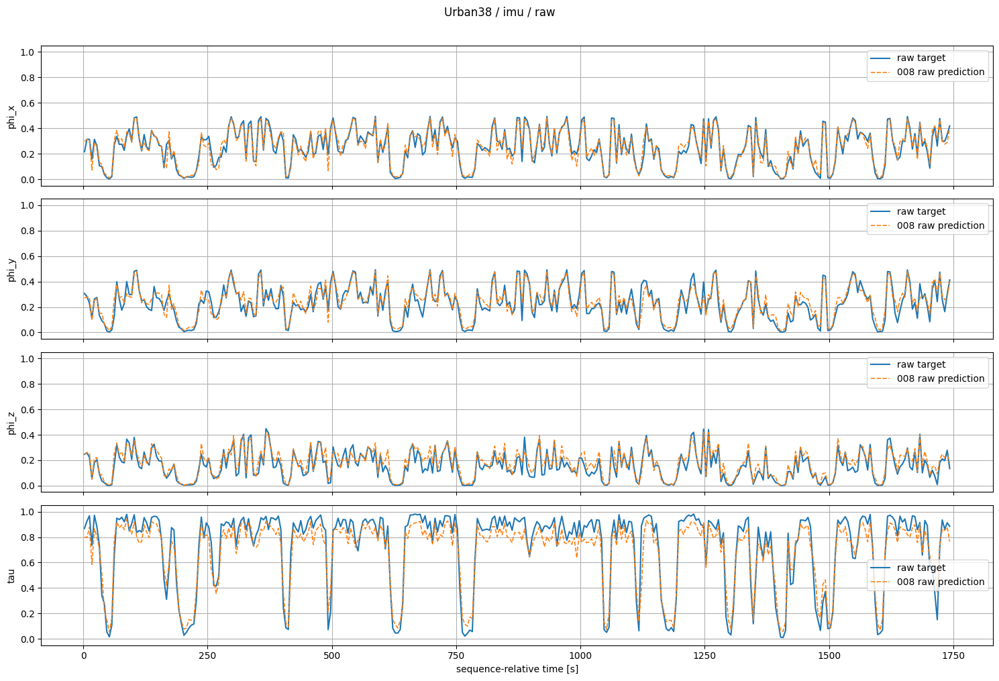

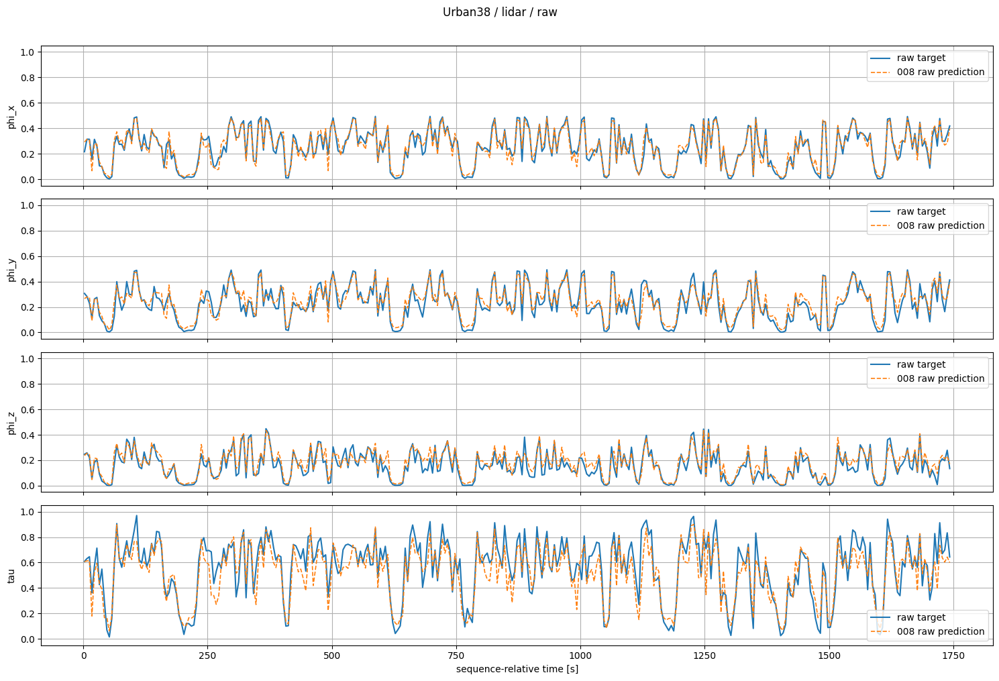

In [25]:
plot_condition_over_time(
    "raw"
)


## 18. Frame randomization only


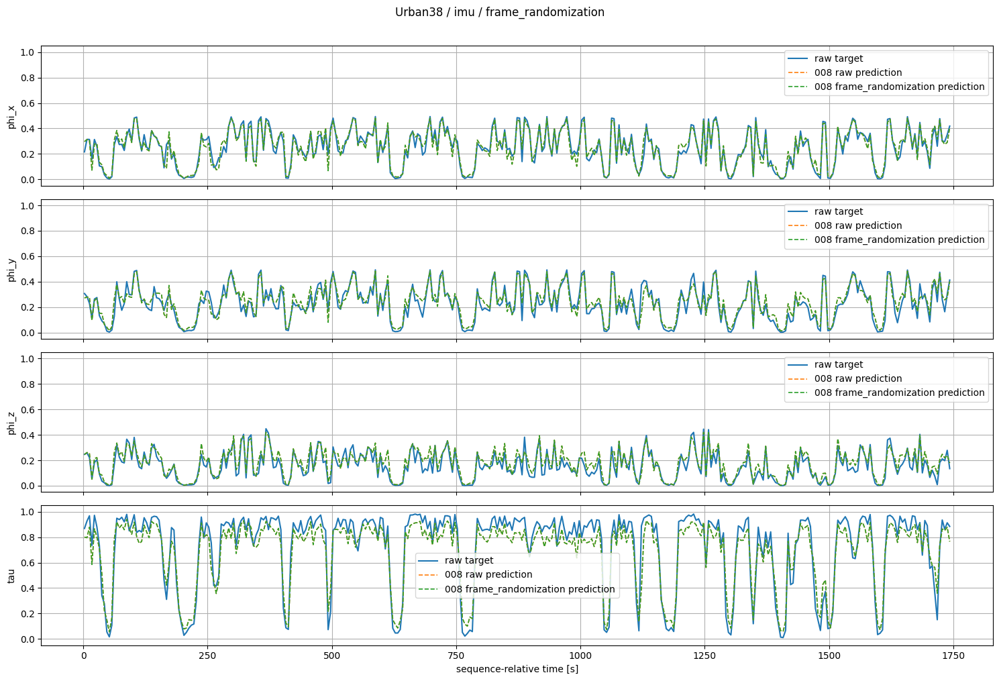

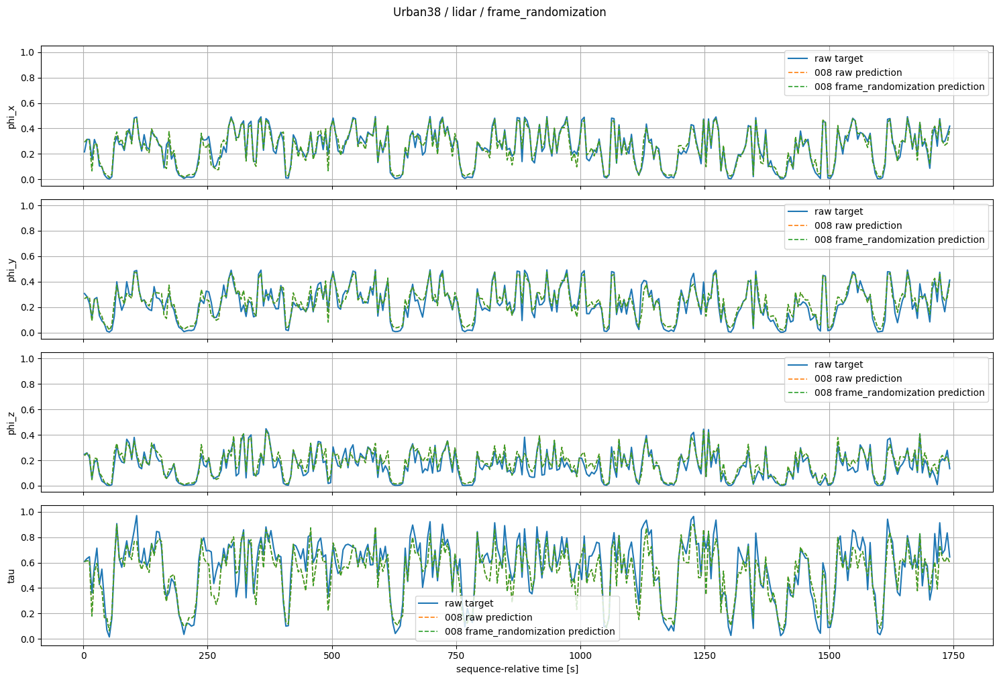

In [26]:
plot_condition_over_time(
    "frame_randomization"
)


## 19. Prior perturbation only


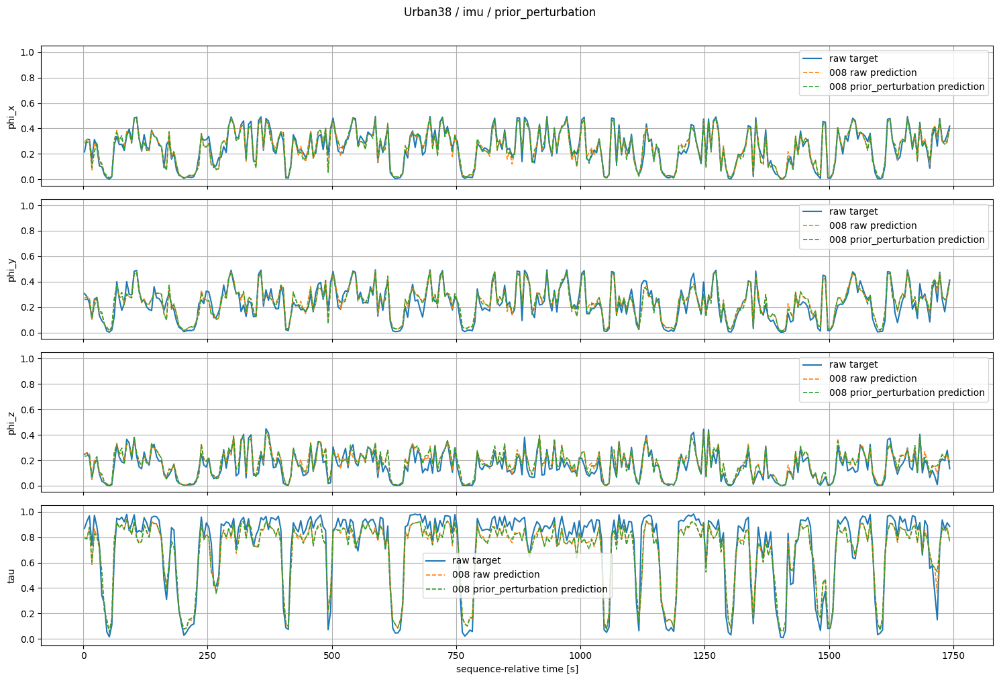

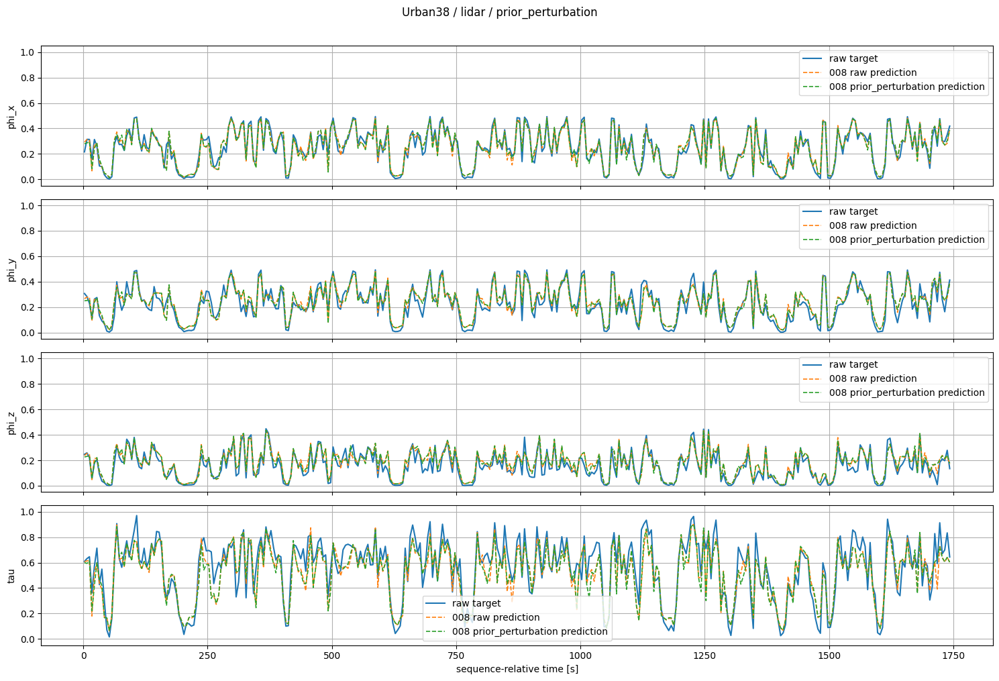

In [27]:
plot_condition_over_time(
    "prior_perturbation"
)


## 20. Measurement noise only


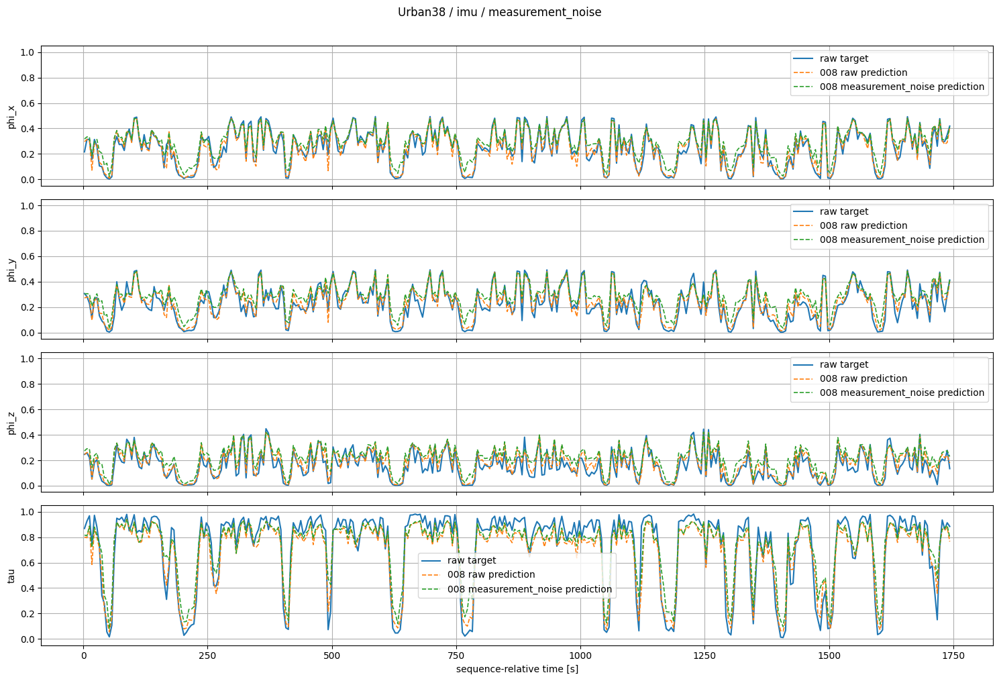

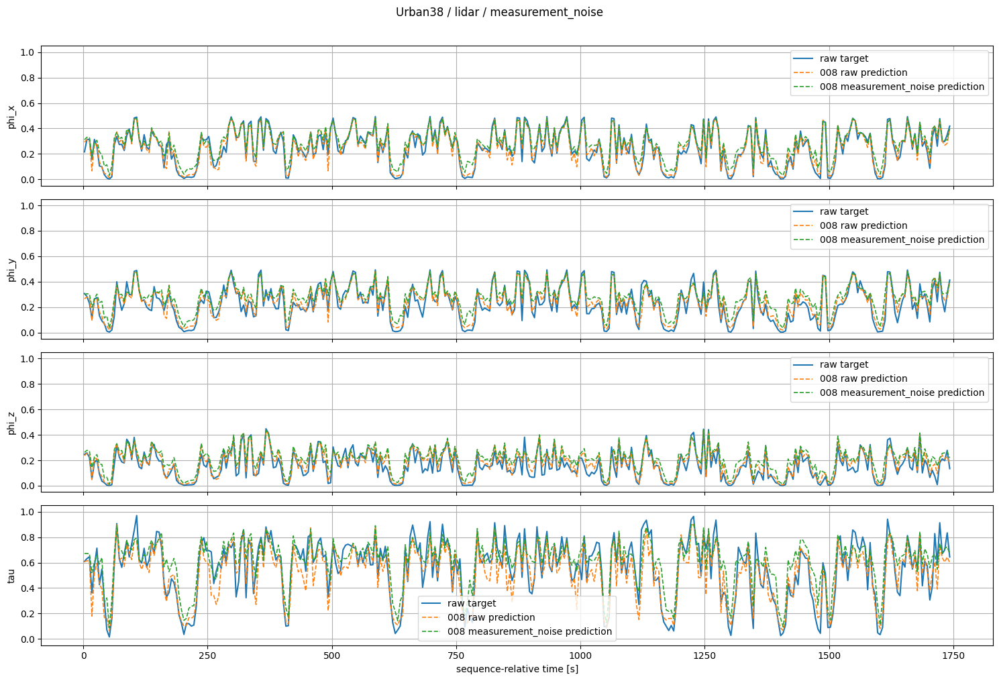

In [28]:
plot_condition_over_time(
    "measurement_noise"
)


## 21. Sampling-rate augmentation only


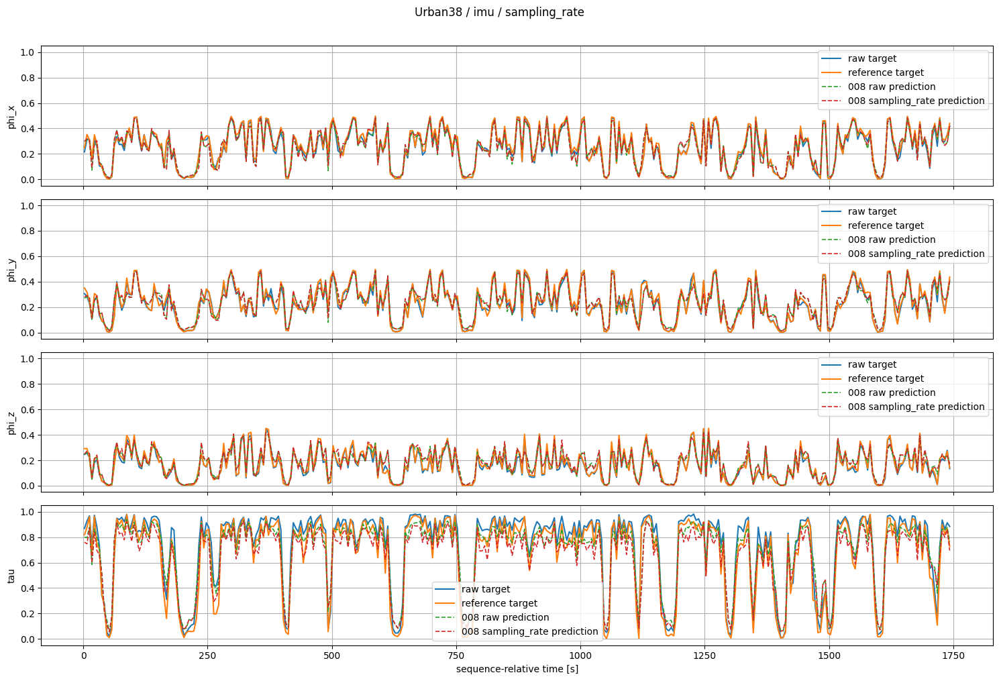

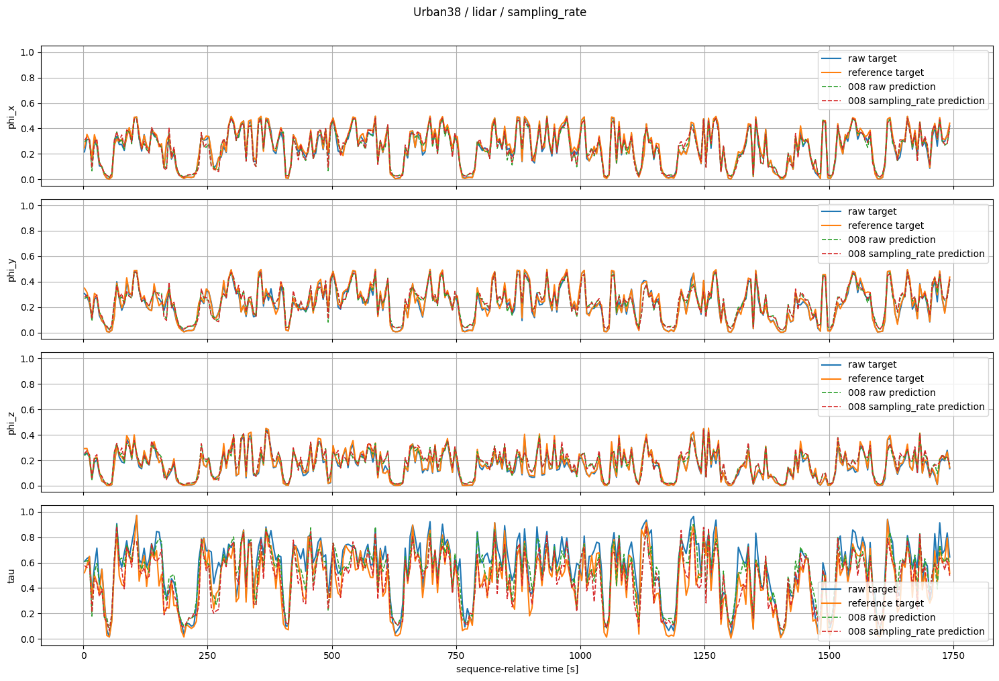

In [29]:
plot_condition_over_time(
    "sampling_rate"
)


## 22. Combined nuisance augmentations


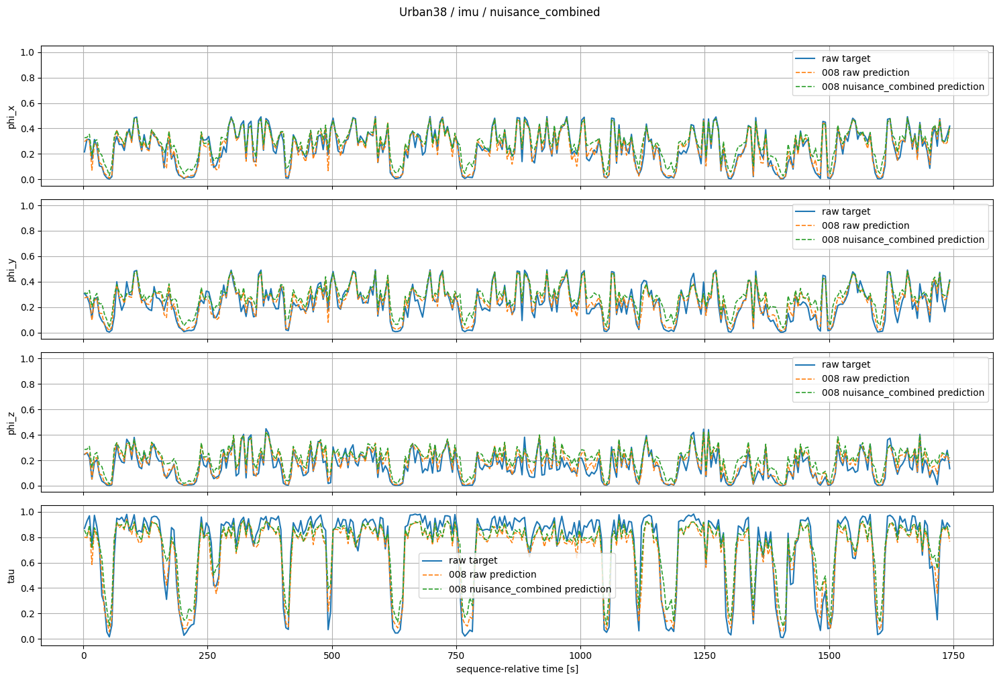

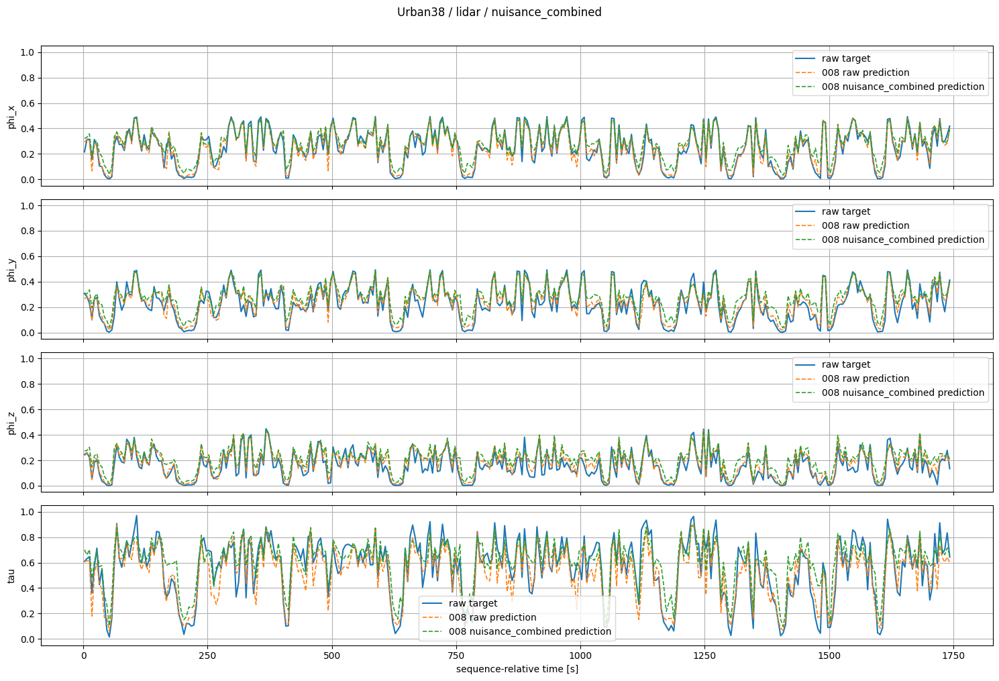

In [30]:
plot_condition_over_time(
    "nuisance_combined"
)


## 23. Full augmentation combination used for checkpoint 008


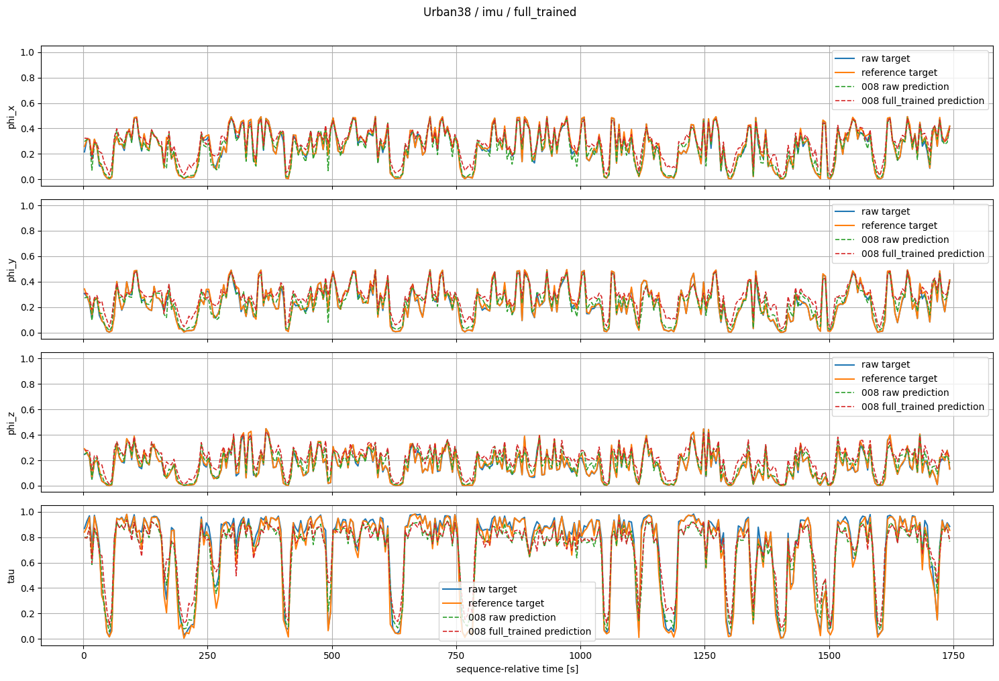

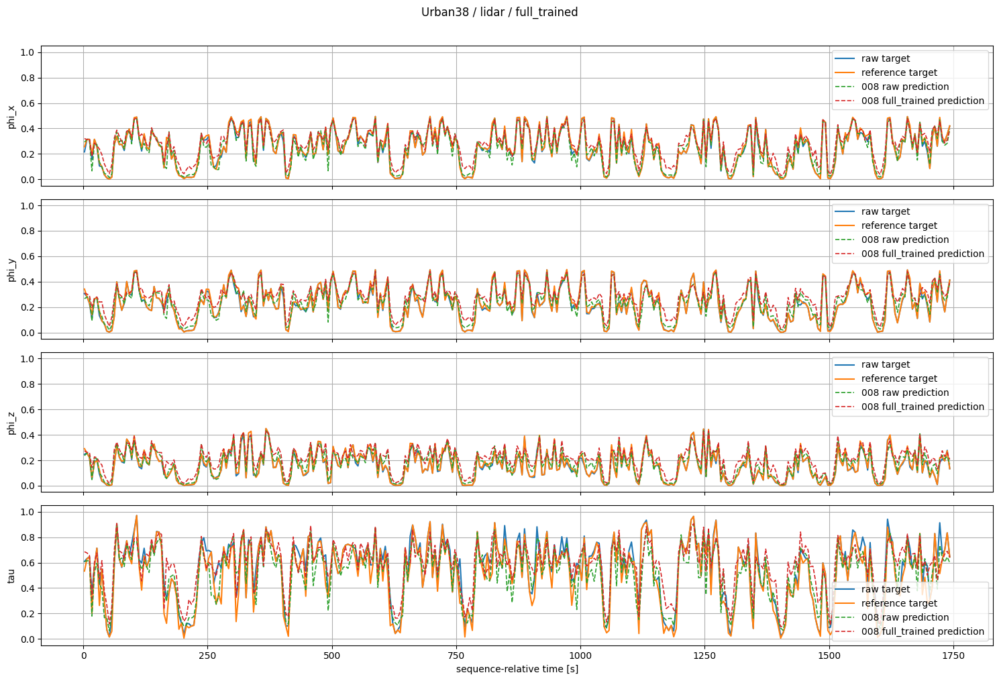

In [31]:
plot_condition_over_time(
    "full_trained"
)


## 24. Calibration-event stress test

Vertical lines mark sampled event starts for the calibration group shown in the figure. Shaded regions show the sampled transition duration.

The `static Fisher on evented window` curve is exploratory. It evaluates the existing static-calibration Fisher machinery on measurements generated under a changing calibration and should not automatically be treated as a future event-training ground truth.


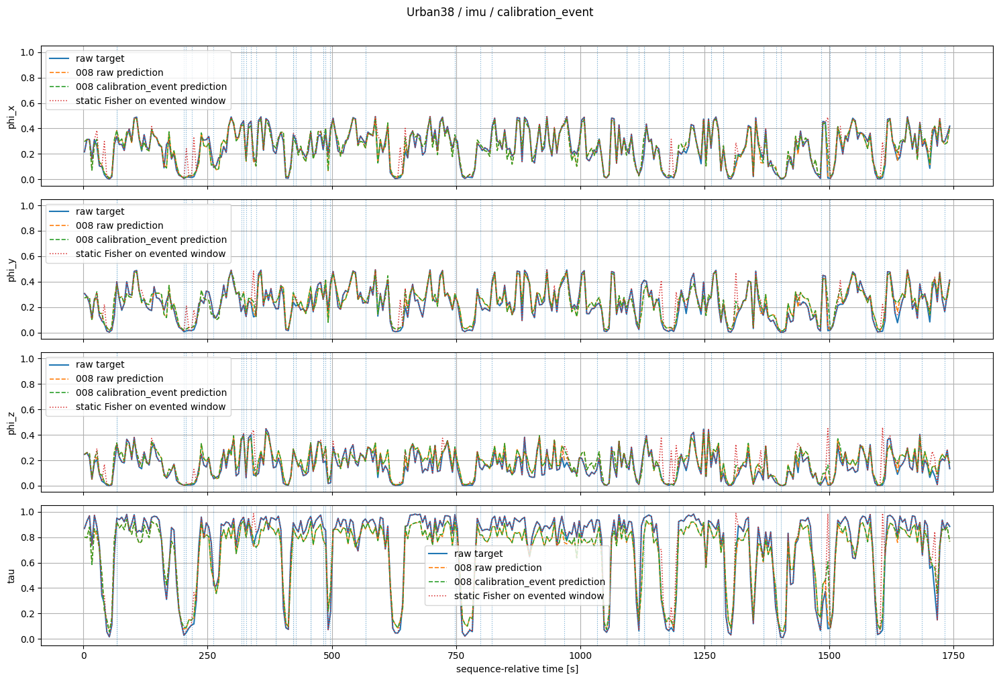

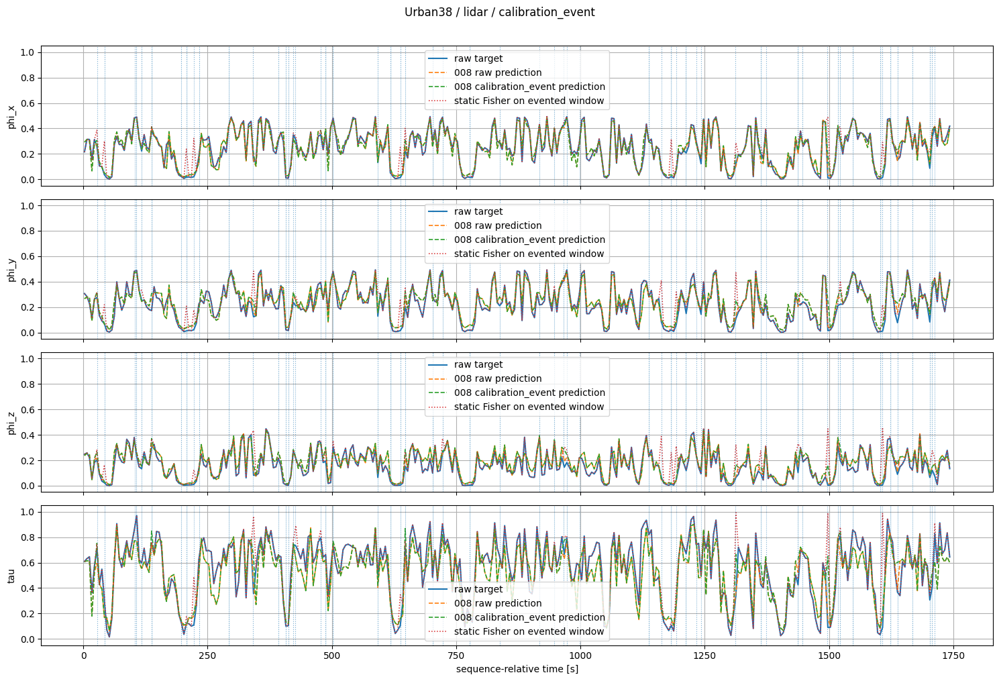

In [32]:
plot_condition_over_time(
    "calibration_event",
    show_static_event_fisher=True,
)


## 25. Optional: full trained augmentations plus calibration events


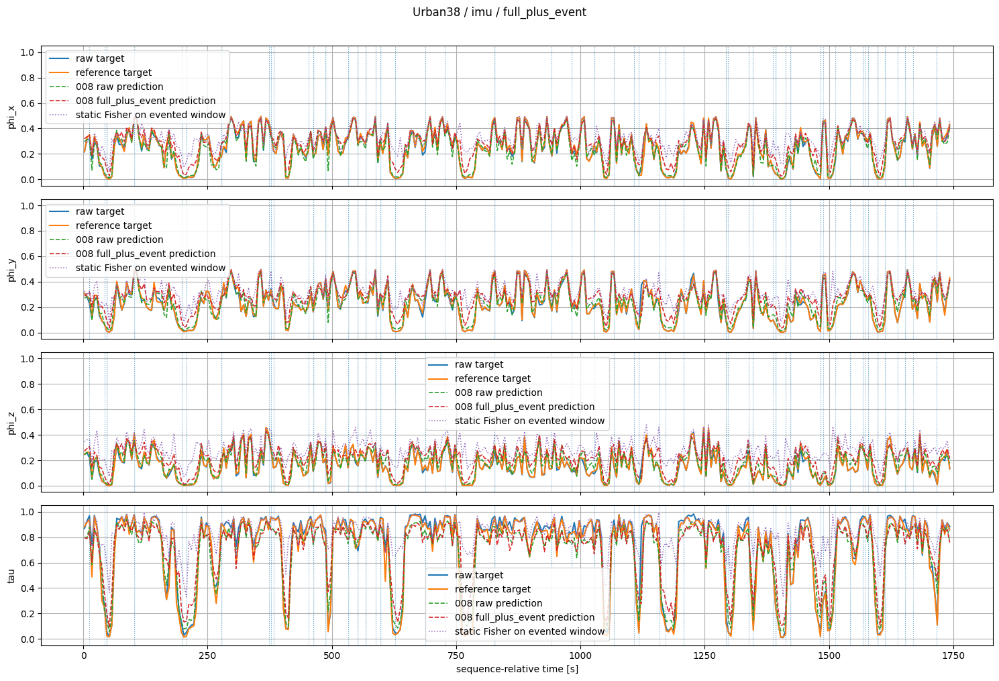

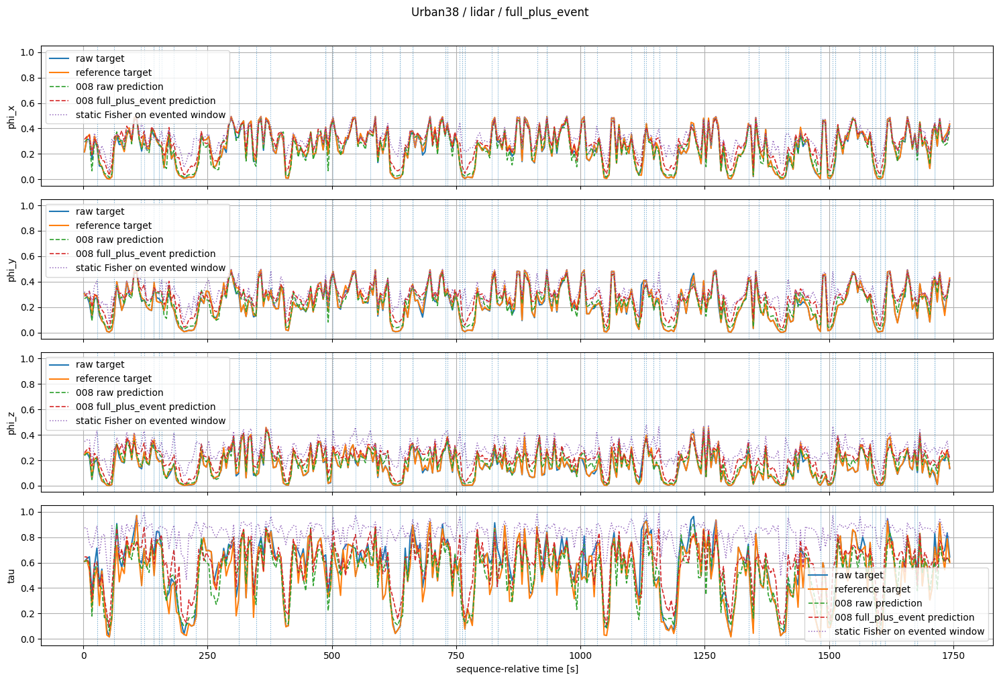

In [33]:
if RUN_FULL_PLUS_EVENT_STRESS_TEST:
    plot_condition_over_time(
        "full_plus_event",
        show_static_event_fisher=True,
    )


## 26. Sampling-rate temporal response


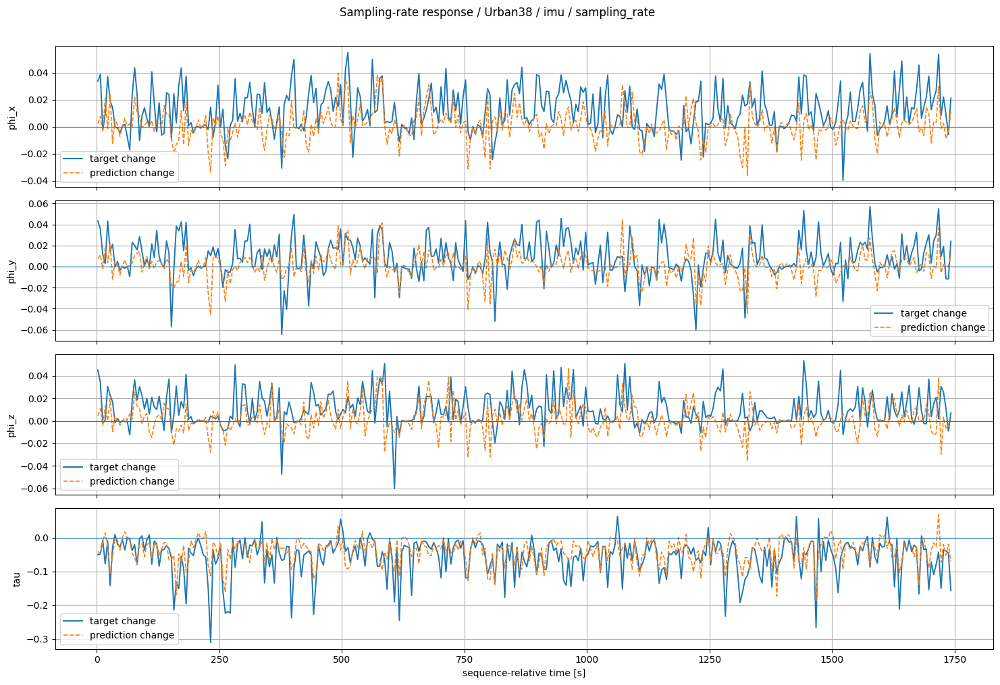

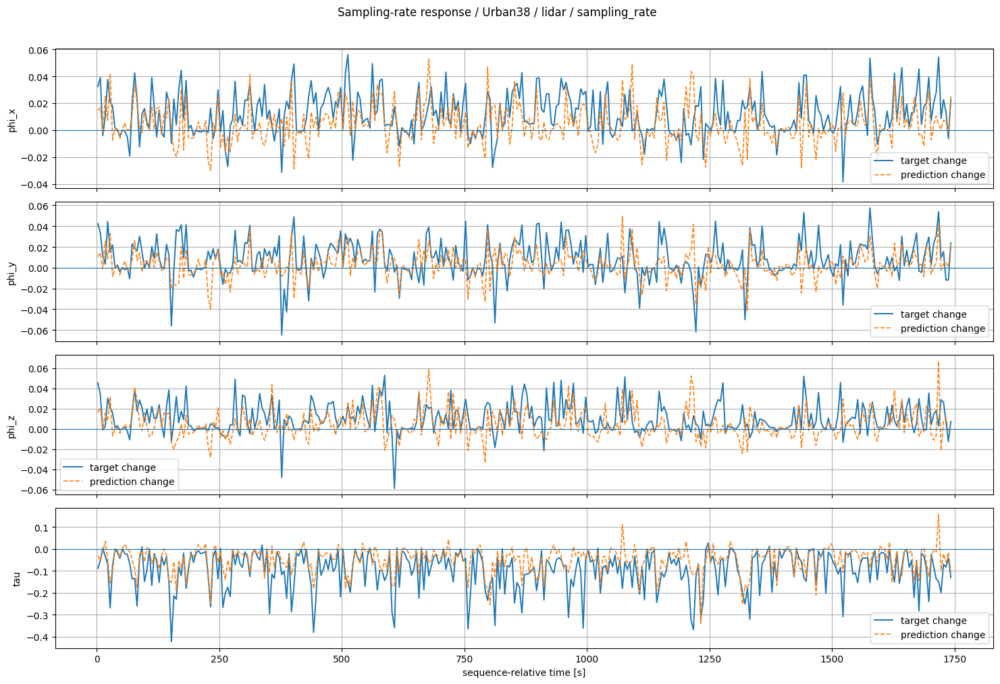

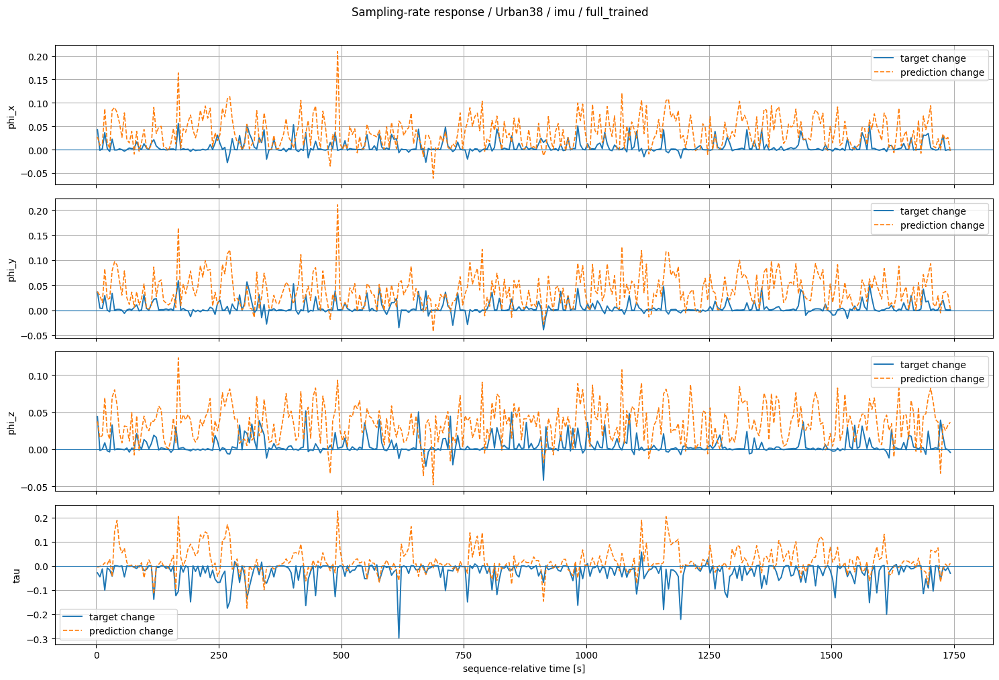

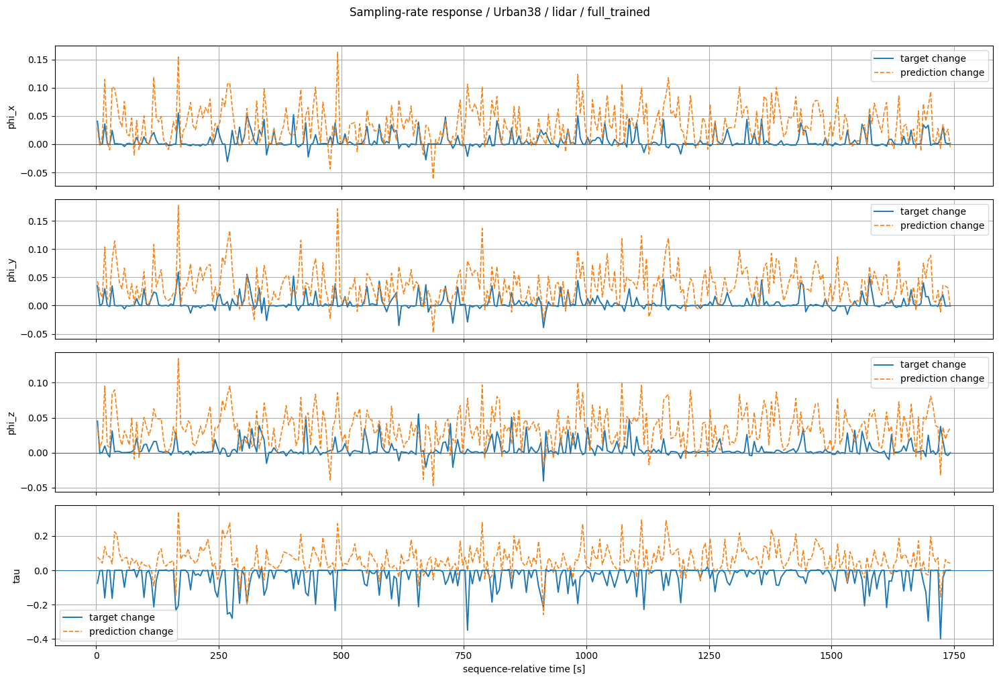

In [34]:
def plot_sampling_response(condition_name):
    if condition_name not in {
        "sampling_rate",
        "full_trained",
        "full_plus_event",
    }:
        raise ValueError("Sampling-response plot requires a sampling-rate condition.")

    condition_data = temporal_results[
        temporal_results["condition"] == condition_name
    ]

    for calibration_key in CALIBRATION_KEYS:
        fig, axes = plt.subplots(
            len(INFORMATIVE_COMPONENTS),
            1,
            figsize=(15, 10),
            sharex=True,
        )

        for axis, component_name in zip(
            axes,
            INFORMATIVE_COMPONENTS,
        ):
            subset = condition_data[
                (condition_data["calibration"] == calibration_key)
                & (condition_data["component"] == component_name)
            ].sort_values(
                "sequence_position"
            )

            target_delta = (
                subset["reference_target"].to_numpy()
                - subset["raw_target"].to_numpy()
            )

            prediction_delta = (
                subset["condition_prediction"].to_numpy()
                - subset["raw_prediction"].to_numpy()
            )

            axis.plot(
                subset["time_s"],
                target_delta,
                label="target change",
                linewidth=1.4,
            )

            axis.plot(
                subset["time_s"],
                prediction_delta,
                linestyle="--",
                label="prediction change",
                linewidth=1.2,
            )

            axis.axhline(
                0.0,
                linewidth=0.8,
            )

            axis.set_ylabel(
                component_name
            )

            axis.grid(
                True
            )

            axis.legend()

        axes[-1].set_xlabel(
            "sequence-relative time [s]"
        )

        fig.suptitle(
            f"Sampling-rate response / {SEQUENCE_NAME} / {calibration_key} / {condition_name}",
            y=1.01,
        )

        fig.tight_layout()

        plt.show()


plot_sampling_response(
    "sampling_rate"
)

plot_sampling_response(
    "full_trained"
)


## 27. Event-local prediction shifts


In [35]:
def event_local_shift_table(condition_name):
    if condition_name not in EVENT_CONDITIONS:
        raise ValueError("Condition does not contain calibration events.")

    data = temporal_results[
        (temporal_results["condition"] == condition_name)
        & temporal_results["component"].isin(INFORMATIVE_COMPONENTS)
    ].copy()

    data["abs_prediction_shift"] = np.abs(
        data["condition_prediction"]
        - data["raw_prediction"]
    )

    summary = (
        data
        .groupby(
            [
                "calibration",
                "component",
            ]
        )
        .agg(
            mean_abs_shift=(
                "abs_prediction_shift",
                "mean",
            ),
            p90_abs_shift=(
                "abs_prediction_shift",
                lambda values: float(
                    np.quantile(
                        values,
                        0.90,
                    )
                ),
            ),
            max_abs_shift=(
                "abs_prediction_shift",
                "max",
            ),
        )
        .reset_index()
    )

    return summary


display(
    event_local_shift_table(
        "calibration_event"
    ).style.format({
        "mean_abs_shift": "{:.4f}",
        "p90_abs_shift": "{:.4f}",
        "max_abs_shift": "{:.4f}",
    })
)


,calibration,component,mean_abs_shift,p90_abs_shift,max_abs_shift
0,imu,phi_x,0.0024,0.0021,0.1861
1,imu,phi_y,0.0031,0.0025,0.2131
2,imu,phi_z,0.0028,0.0021,0.1506
3,imu,tau,0.0035,0.0031,0.4655
4,lidar,phi_x,0.0023,0.0018,0.1559
5,lidar,phi_y,0.0031,0.0027,0.2065
6,lidar,phi_z,0.0028,0.0022,0.1438
7,lidar,tau,0.0085,0.0086,0.4973


## 28. Interpretation checklist

When reading these plots:

### Raw
The learned curve should follow the computed target smoothly through the held-out sequence without long systematic offsets or isolated pathological spikes.

### Frame randomization
The prediction should be essentially unchanged relative to the raw prediction.

### Prior perturbation
The prediction should remain close to the raw-target trajectory even though the supplied current calibration is perturbed.

### Measurement noise
The prediction is intentionally compared with the **raw target**, not the Fisher value obtained from one noisy realization. Look for isolated noise-induced spikes and systematic loss of tracking.

### Sampling rate
The prediction should follow the **recomputed sampled target**. In particular, `tau` should move when reduced sampling genuinely changes temporal information.

### Combined nuisance augmentations
This checks whether individually tolerable nuisance transformations interact badly when applied together.

### Full trained combination
This is the closest sanity check to checkpoint 008's actual training distribution. The reference target changes only because of sampling-rate reduction; frame/prior/noise do not change the desired target.

### Calibration events
This is an out-of-distribution stress test for checkpoint 008. Vertical lines mark event starts and shaded spans show event transitions. The static event-window Fisher is diagnostic only.

For later event-aware observability training, a coherent first target definition is to estimate observability of the **final calibration from post-transition measurements**, rather than treating the complete mixed pre/post-event window as if it were generated by one static calibration.
